<!-- solution3-narrative -->
# Solution 3  Pretrained YAMNet Embeddings with Support Vector Machine

## Aim

This notebook evaluates whether representations learned by the pretrained **YAMNet** audio network generalize better to noisy ESC-50 recordings than features learned only from ESC-50.

The experiment uses YAMNet as a frozen feature extractor and trains an RBF support vector machine on the resulting embeddings. Models are trained on clean audio and evaluated under **Clean, 20 dB, 10 dB, 5 dB, and 0 dB** Gaussian-noise conditions.

### Research question

> How much does additive background noise affect environmental sound classification, and can externally pretrained audio embeddings improve robustness?

### Main stages

1. Load and validate ESC-50.
2. Standardize each recording to a five-second, 16 kHz mono waveform.
3. Generate deterministic noisy versions at four signal-to-noise ratios.
4. Extract and mean-pool 1,024-dimensional YAMNet embeddings.
5. Apply fold-local scaling, feature selection, and SVM tuning.
6. Evaluate accuracy, macro-F1, class-wise F1, and confusion matrices.

## Environment and dependencies

The following cell installs the libraries required by the Colab runtime. When running locally, install the project requirements before opening the notebook.


In [1]:
!pip install -q librosa soundfile tensorflow tensorflow-hub scikit-learn matplotlib seaborn pandas tqdm joblib

<!-- solution3-narrative -->
## Dataset acquisition

The ESC-50 archive is downloaded from its official GitHub repository and extracted into the Colab workspace. ESC-50 contains **2,000 five-second recordings**, **50 balanced classes**, and **five official folds**.

The dataset is distributed separately under the **CC BY-NC 3.0** license and is not stored with the project repository.


In [2]:
import os
import zipfile
import urllib.request
DATASET_URL = "https://github.com/karolpiczak/ESC-50/archive/refs/heads/master.zip"
ZIP_PATH = "/content/ESC-50.zip"
EXTRACT_PATH = "/content/"

if not os.path.exists("/content/ESC-50-master"):
    urllib.request.urlretrieve(DATASET_URL, ZIP_PATH)
    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(EXTRACT_PATH)

DATASET_PATH = "/content/ESC-50-master"
AUDIO_PATH = os.path.join(DATASET_PATH, "audio")
METADATA_PATH = os.path.join(DATASET_PATH, "meta", "esc50.csv")

print("Dataset downloaded successfully!")
print("Audio directory:", AUDIO_PATH)
print("Metadata:", METADATA_PATH)


Dataset downloaded successfully!
Audio directory: /content/ESC-50-master/audio
Metadata: /content/ESC-50-master/meta/esc50.csv


<!-- solution3-narrative -->
## Imports, reproducibility, and experiment configuration

All random-number generators use seed `42`. Audio is standardized to 16 kHz and five seconds because YAMNet expects mono floating-point waveforms at 16 kHz.

The output directory stores metrics, predictions, plots, cached embeddings, and the final classifier. Large caches and model files are excluded from the GitHub repository.


In [3]:
import os
import time
import hashlib
import pickle
import random
import warnings
import numpy as np
import pandas as pd
import librosa
import soundfile as sf
import tensorflow as tf
import tensorflow_hub as hub
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score,f1_score,confusion_matrix,classification_report)
import joblib
from sklearn.feature_selection import SelectKBest, f_classif

warnings.filterwarnings("ignore")

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

SAMPLE_RATE = 16000
AUDIO_DURATION = 5
EXPECTED_SAMPLES = SAMPLE_RATE * AUDIO_DURATION

SNR_LEVELS = ["Clean", "20 dB", "10 dB","5dB", "0 dB"]

SNR_VALUES = {
    "Clean": None,
    "20 dB": 20,
    "10 dB": 10,
    "5 dB": 5,
    "0 dB": 0
}

OUTPUT_PATH = "/content/model3_results"
os.makedirs(OUTPUT_PATH, exist_ok=True)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))


/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


<!-- solution3-narrative -->
## Inspect the ESC-50 metadata

Before training, the metadata is checked for the expected number of recordings, classes, and official folds. These checks protect the experiment from silently running on an incomplete or incorrectly extracted dataset.


In [4]:
metadata = pd.read_csv(METADATA_PATH)

print("Dataset shape:", metadata.shape)
print("\nFirst five records:")
display(metadata.head())

print("\nNumber of recordings:", len(metadata))
print("Number of classes:", metadata["category"].nunique())

print("\nRecordings per fold:")
print(metadata["fold"].value_counts().sort_index())

print("\nClass distribution:")
print(metadata["category"].value_counts().sort_index())


Dataset shape: (2000, 7)

First five records:


,filename,fold,target,category,esc10,src_file,take
0,1-100032-A-0.wav,1,0,dog,True,100032,A
1,1-100038-A-14.wav,1,14,chirping_birds,False,100038,A
2,1-100210-A-36.wav,1,36,vacuum_cleaner,False,100210,A
3,1-100210-B-36.wav,1,36,vacuum_cleaner,False,100210,B
4,1-101296-A-19.wav,1,19,thunderstorm,False,101296,A



Number of recordings: 2000
Number of classes: 50

Recordings per fold:
fold
1    400
2    400
3    400
4    400
5    400
Name: count, dtype: int64

Class distribution:
category
airplane            40
breathing           40
brushing_teeth      40
can_opening         40
car_horn            40
cat                 40
chainsaw            40
chirping_birds      40
church_bells        40
clapping            40
clock_alarm         40
clock_tick          40
coughing            40
cow                 40
crackling_fire      40
crickets            40
crow                40
crying_baby         40
dog                 40
door_wood_creaks    40
door_wood_knock     40
drinking_sipping    40
engine              40
fireworks           40
footsteps           40
frog                40
glass_breaking      40
hand_saw            40
helicopter          40
hen                 40
insects             40
keyboard_typing     40
laughing            40
mouse_click         40
pig                 40
pouring_water    

In [5]:
label_encoder = LabelEncoder()

metadata["label"] = label_encoder.fit_transform(metadata["category"])

CLASS_NAMES = label_encoder.classes_
NUM_CLASSES = len(CLASS_NAMES)

print("Number of classes:", NUM_CLASSES)
print("\nClass mapping:")

for index, name in enumerate(CLASS_NAMES):
    print(index, ":", name)


Number of classes: 50

Class mapping:
0 : airplane
1 : breathing
2 : brushing_teeth
3 : can_opening
4 : car_horn
5 : cat
6 : chainsaw
7 : chirping_birds
8 : church_bells
9 : clapping
10 : clock_alarm
11 : clock_tick
12 : coughing
13 : cow
14 : crackling_fire
15 : crickets
16 : crow
17 : crying_baby
18 : dog
19 : door_wood_creaks
20 : door_wood_knock
21 : drinking_sipping
22 : engine
23 : fireworks
24 : footsteps
25 : frog
26 : glass_breaking
27 : hand_saw
28 : helicopter
29 : hen
30 : insects
31 : keyboard_typing
32 : laughing
33 : mouse_click
34 : pig
35 : pouring_water
36 : rain
37 : rooster
38 : sea_waves
39 : sheep
40 : siren
41 : sneezing
42 : snoring
43 : thunderstorm
44 : toilet_flush
45 : train
46 : vacuum_cleaner
47 : washing_machine
48 : water_drops
49 : wind


<!-- solution3-narrative -->
## Audio preprocessing

Every recording is converted to mono, resampled to 16 kHz, and cropped or zero-padded to exactly five seconds. Peak normalization keeps waveform values within a consistent numerical range before YAMNet inference.

This preprocessing is applied identically to clean and noisy evaluation conditions.


In [6]:
#preprocessing
#Every recording will be converted into:
#- Mono audio.
#- 16 kHz sampling rate.
#- Five-second waveform.

def load_audio(file_path):

    audio, sr = librosa.load(
        file_path,
        sr=SAMPLE_RATE,
        mono=True
    )

    if len(audio) > EXPECTED_SAMPLES:
        audio = audio[:EXPECTED_SAMPLES]

    elif len(audio) < EXPECTED_SAMPLES:
        audio = np.pad(
            audio,
            (0, EXPECTED_SAMPLES - len(audio))
        )

    audio = audio.astype(np.float32)

    peak = np.max(np.abs(audio))

    if peak > 1e-8:
        audio = audio * (0.99 / peak)

    return audio.astype(np.float32)

sample_file = os.path.join(
    AUDIO_PATH,
    metadata.iloc[0]["filename"]
)

sample_audio = load_audio(sample_file)

print("Audio shape:", sample_audio.shape)
print("Sampling rate:", SAMPLE_RATE)
print("Duration:", len(sample_audio) / SAMPLE_RATE, "seconds")


Audio shape: (80000,)
Sampling rate: 16000
Duration: 5.0 seconds


<!-- solution3-narrative -->
## Controlled Gaussian-noise generation

For a clean waveform with power $P_s$ and a target signal-to-noise ratio $SNR_{dB}$, the required noise power is

$$P_n = rac{P_s}{10^{SNR_{dB}/10}}.$$

Gaussian noise is scaled to this power and added to the clean signal. A filename- and SNR-dependent seed makes every noisy recording deterministic and reproducible.

- **20 dB:** light corruption
- **10 dB:** clearly audible background noise
- **5 dB:** strong corruption
- **0 dB:** signal and noise have equal power


In [7]:
#Generate noisy audio at different SNR levels
def generate_noisy_audio(clean_audio, snr_db, seed=42):

    clean_audio = np.asarray(clean_audio, dtype=np.float32)
    rng = np.random.default_rng(seed)

    noise = rng.normal(
        loc=0.0,
        scale=1.0,
        size=len(clean_audio)
    ).astype(np.float32)

    signal_power = np.mean(clean_audio ** 2)
    noise_power = np.mean(noise ** 2)

    if signal_power < 1e-12:
        return clean_audio.copy()
    target_noise_power = (
        signal_power / (10 ** (snr_db / 10))
    )

    alpha = np.sqrt(
        target_noise_power / (noise_power + 1e-12)
    )

    noisy_audio = clean_audio + alpha * noise

    peak = np.max(np.abs(noisy_audio))

    if peak > 0.99:
        noisy_audio = noisy_audio * (0.99 / peak)

    return noisy_audio.astype(np.float32)

test_clean = sample_audio

test_noisy = generate_noisy_audio(
    test_clean,
    snr_db=10,
    seed=42
)

print("Clean audio power:", np.mean(test_clean ** 2))
print("Noisy audio power:", np.mean(test_noisy ** 2))


Clean audio power: 0.0017410731
Noisy audio power: 0.0018873708


<!-- solution3-narrative -->
## Pretrained YAMNet representation

YAMNet is loaded from TensorFlow Hub and kept frozen. It was pretrained on the external **AudioSet** corpus, so this solution is a transfer-learning approach rather than an ESC-50-only model.

YAMNet produces a sequence of 1,024-dimensional frame embeddings. Mean pooling converts the variable-length sequence into one fixed-size vector per recording.


In [8]:
YAMNET_URL = "https://tfhub.dev/google/yamnet/1"
yamnet_model = hub.load(YAMNET_URL)

print("YAMNet loaded successfully!")


YAMNet loaded successfully!


In [9]:

def extract_yamnet_embedding(audio):

    waveform = tf.convert_to_tensor(
        audio,
        dtype=tf.float32
    )

    scores, embeddings, spectrogram = yamnet_model(waveform)

    # Mean pooling
    recording_embedding = tf.reduce_mean(
        embeddings,
        axis=0
    )

    return recording_embedding.numpy().astype(np.float32)


sample_embedding = extract_yamnet_embedding(sample_audio)

print("Embedding shape:", sample_embedding.shape)
print("Embedding dimensions:", len(sample_embedding))

assert sample_embedding.shape == (1024,)


Embedding shape: (1024,)
Embedding dimensions: 1024


<!-- solution3-narrative -->
## Extract embeddings for every noise condition

Each ESC-50 recording is represented under five conditions: Clean, 20 dB, 10 dB, 5 dB, and 0 dB. The resulting array has the conceptual shape

`recordings × conditions × embedding dimensions`.

Embedding extraction is the expensive pretrained-network stage, so the complete array is cached for reuse.


In [10]:
CONDITIONS = ["Clean", "20 dB", "10 dB", "5 dB", "0 dB"]

CACHE_PATH = os.path.join(
    OUTPUT_PATH,
    "yamnet_embeddings.npz"
)

def stable_seed(filename, snr):
    key = f"{filename}_{snr}_{SEED}".encode("utf-8")
    digest = hashlib.sha256(key).hexdigest()
    return int(digest[:8], 16)


if os.path.exists(CACHE_PATH):
    os.remove(CACHE_PATH)

    print("Loading previously extracted embeddings...")

    cached = np.load(CACHE_PATH)

    X = cached["X"]
    y = cached["y"]
    folds = cached["folds"]

else:

    X = np.zeros(
        (len(metadata), len(CONDITIONS), 1024),
        dtype=np.float32
    )

    y = metadata["label"].to_numpy(dtype=np.int64)
    folds = metadata["fold"].to_numpy(dtype=np.int64)

    start_time = time.time()

    for i, row in tqdm(
        metadata.iterrows(),
        total=len(metadata),
        desc="Extracting YAMNet embeddings"
    ):

        filename = row["filename"]

        file_path = os.path.join(
            AUDIO_PATH,
            filename
        )

        clean_audio = load_audio(file_path)

        for condition_index, condition in enumerate(CONDITIONS):

            if condition == "Clean":

                audio = clean_audio

            else:

                snr = SNR_VALUES[condition]

                audio = generate_noisy_audio(
                    clean_audio,
                    snr_db=snr,
                    seed=stable_seed(filename, snr)
                )

            embedding = extract_yamnet_embedding(audio)

            X[i, condition_index, :] = embedding

    np.savez_compressed(
        CACHE_PATH,
        X=X,
        y=y,
        folds=folds
    )

    print("Embedding extraction completed!")

    print(
        "Total extraction time:",
        round((time.time() - start_time) / 60, 2),
        "minutes"
    )


print("Feature array shape:", X.shape)
print("Labels shape:", y.shape)
print("Fold array shape:", folds.shape)


Extracting YAMNet embeddings:   0%|          | 0/2000 [00:00<?, ?it/s]

Embedding extraction completed!
Total extraction time: 1.26 minutes
Feature array shape: (2000, 5, 1024)
Labels shape: (2000,)
Fold array shape: (2000,)


<!-- solution3-narrative -->
## Embedding quality checks

The cached representation is checked for missing values, infinite values, zero vectors, and unexpected numerical ranges before it is supplied to the classifier.


In [11]:
print("NaN values:", np.isnan(X).sum())
print("Infinite values:", np.isinf(X).sum())
print("Zero embeddings:", np.sum(np.linalg.norm(X, axis=2) == 0))

print("Mean:", X.mean())
print("Standard deviation:", X.std())

NaN values: 0
Infinite values: 0
Zero embeddings: 0
Mean: 0.08988318
Standard deviation: 0.3313489


<!-- solution3-narrative -->
## Leakage-controlled five-fold evaluation

The five official ESC-50 folds define the outer evaluation. For each outer test fold:

1. The remaining four folds form the training set.
2. `StandardScaler` is fitted only on the training embeddings.
3. ANOVA `SelectKBest` is fitted only on the training embeddings.
4. SVM hyperparameters are selected with three-fold inner cross-validation.
5. The selected pipeline predicts the clean and noisy versions of the untouched outer test fold.

The same clean-trained classifier is evaluated at every SNR. This isolates the effect of changing evaluation conditions and prevents the outer test fold from influencing feature selection or tuning.


In [12]:

from sklearn.model_selection import GridSearchCV

results = []

all_predictions = {
    condition: np.full(len(metadata), -1, dtype=np.int64)
    for condition in CONDITIONS
}

all_test_labels = y.copy()

fold_training_times = []
fold_inference_times = []
best_parameters = []

param_grid = {
    "feature_selection__k": [128, 256, 512, "all"],
    "svm__C": [0.1, 1, 10, 50, 100],
    "svm__gamma": ["scale", 0.001, 0.01, 0.1]
}

for test_fold in range(1, 6):

    print(f"\n========== FOLD {test_fold} ==========")

    train_indices = np.where(folds != test_fold)[0]
    test_indices = np.where(folds == test_fold)[0]

    X_train = X[train_indices, 0, :].astype(np.float32)
    y_train = y[train_indices]

    svm_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("feature_selection", SelectKBest(score_func=f_classif)),
        ("svm", SVC(kernel="rbf", class_weight=None))
    ])

    grid = GridSearchCV(
        estimator=svm_pipeline,
        param_grid=param_grid,
        cv=3,
        scoring="f1_macro",
        n_jobs=-1,
        refit=True
    )

    train_start = time.time()
    grid.fit(X_train, y_train)

    training_time = time.time() - train_start
    fold_training_times.append(training_time)

    best_model = grid.best_estimator_
    best_parameters.append({
        "Fold": test_fold,
        "Best_C": grid.best_params_["svm__C"],
        "Best_Gamma": grid.best_params_["svm__gamma"],
        "CV_Macro_F1": grid.best_score_
    })

    print("Training recordings:", len(train_indices))
    print("Testing recordings:", len(test_indices))
    print("Best parameters:", grid.best_params_)
    print("Best CV Macro-F1:", round(grid.best_score_, 4))
    print("Training + tuning time:", round(training_time, 2), "seconds")

    for condition_index, condition in enumerate(CONDITIONS):

        X_test = X[test_indices, condition_index, :]
        y_test = y[test_indices]

        inference_start = time.time()

        predictions = best_model.predict(X_test)

        inference_time = time.time() - inference_start

        fold_inference_times.append(
            inference_time / len(test_indices)
        )

        all_predictions[condition][test_indices] = predictions

        accuracy = accuracy_score(y_test, predictions)

        macro_f1 = f1_score(
            y_test,
            predictions,
            average="macro",
            zero_division=0
        )

        results.append({
            "Fold": test_fold,
            "Condition": condition,
            "Accuracy": accuracy,
            "Macro_F1": macro_f1,
            "Training_Time_Seconds": training_time,
            "Inference_Time_Per_Sample_Seconds":
                inference_time / len(test_indices)
        })

        print(
            f"{condition}: "
            f"Accuracy = {accuracy:.4f}, "
            f"Macro-F1 = {macro_f1:.4f}"
        )


fold_results = pd.DataFrame(results)
best_parameters_df = pd.DataFrame(best_parameters)

print(
    "Selected number of features:",
    grid.best_params_["feature_selection__k"]
)
print("\nCross-validation completed!")
display(fold_results)
display(best_parameters_df)



========== FOLD 1 ==========
Training recordings: 1600
Testing recordings: 400
Best parameters: {'feature_selection__k': 256, 'svm__C': 10, 'svm__gamma': 'scale'}
Best CV Macro-F1: 0.8221
Training + tuning time: 115.85 seconds
Clean: Accuracy = 0.7575, Macro-F1 = 0.7554
20 dB: Accuracy = 0.6150, Macro-F1 = 0.6011
10 dB: Accuracy = 0.3975, Macro-F1 = 0.3861
5 dB: Accuracy = 0.2700, Macro-F1 = 0.2652
0 dB: Accuracy = 0.1300, Macro-F1 = 0.1195

========== FOLD 2 ==========
Training recordings: 1600
Testing recordings: 400
Best parameters: {'feature_selection__k': 256, 'svm__C': 10, 'svm__gamma': 'scale'}
Best CV Macro-F1: 0.7956
Training + tuning time: 112.05 seconds
Clean: Accuracy = 0.8400, Macro-F1 = 0.8408
20 dB: Accuracy = 0.6500, Macro-F1 = 0.6356
10 dB: Accuracy = 0.4050, Macro-F1 = 0.3982
5 dB: Accuracy = 0.2600, Macro-F1 = 0.2570
0 dB: Accuracy = 0.1200, Macro-F1 = 0.1095

========== FOLD 3 ==========
Training recordings: 1600
Testing recordings: 400
Best parameters: {'feature_s

,Fold,Condition,Accuracy,Macro_F1,Training_Time_Seconds,Inference_Time_Per_Sample_Seconds
0,1,Clean,0.7575,0.755365,115.848058,0.000423
1,1,20 dB,0.6150,0.601066,115.848058,0.000431
2,1,10 dB,0.3975,0.386138,115.848058,0.000490
3,1,5 dB,0.2700,0.265222,115.848058,0.000444
4,1,0 dB,0.1300,0.119451,115.848058,0.000432
5,2,Clean,0.8400,0.840784,112.050604,0.000370
6,2,20 dB,0.6500,0.635573,112.050604,0.000412
7,2,10 dB,0.4050,0.398239,112.050604,0.000376
8,2,5 dB,0.2600,0.257003,112.050604,0.000381
9,2,0 dB,0.1200,0.109549,112.050604,0.000369


,Fold,Best_C,Best_Gamma,CV_Macro_F1
0,1,10,scale,0.822103
1,2,10,scale,0.795576
2,3,100,scale,0.809691
3,4,50,scale,0.799901
4,5,50,scale,0.807324


<!-- solution3-narrative -->
## Aggregate performance across the five test folds

Predictions from the five outer folds are pooled to calculate overall accuracy, macro-F1, and weighted-F1 for each condition. Macro-F1 gives equal importance to all 50 classes and is therefore reported alongside accuracy.


In [13]:

summary_results = []

for condition in CONDITIONS:

    predictions = all_predictions[condition]

    assert np.all(predictions >= 0), (
        f"Missing predictions for {condition}"
    )

    accuracy = accuracy_score(
        all_test_labels,
        predictions
    )

    macro_f1 = f1_score(
        all_test_labels,
        predictions,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        all_test_labels,
        predictions,
        average="weighted",
        zero_division=0
    )

    summary_results.append({
        "Condition": condition,
        "Accuracy": accuracy,
        "Macro_F1": macro_f1,
        "Weighted_F1": weighted_f1
    })


summary_df = pd.DataFrame(summary_results)

print("FINAL MODEL 3 RESULTS")
display(
    summary_df.style.format({
        "Accuracy": "{:.4f}",
        "Macro_F1": "{:.4f}",
        "Weighted_F1": "{:.4f}"
    })
)

summary_df.to_csv(
    os.path.join(OUTPUT_PATH, "model3_summary.csv"),
    index=False
)


FINAL MODEL 3 RESULTS


,Condition,Accuracy,Macro_F1,Weighted_F1
0,Clean,0.8230,0.8238,0.8238
1,20 dB,0.6340,0.6326,0.6326
2,10 dB,0.4085,0.4010,0.4010
3,5 dB,0.2605,0.2569,0.2569
4,0 dB,0.1185,0.1111,0.1111


<!-- solution3-narrative -->
## Noise-robustness visualizations

The following plots show how accuracy and macro-F1 change as SNR decreases. Confusion matrices compare clean performance with the most severe 0 dB condition.

The expected random-classification accuracy for 50 balanced classes is **2%**.


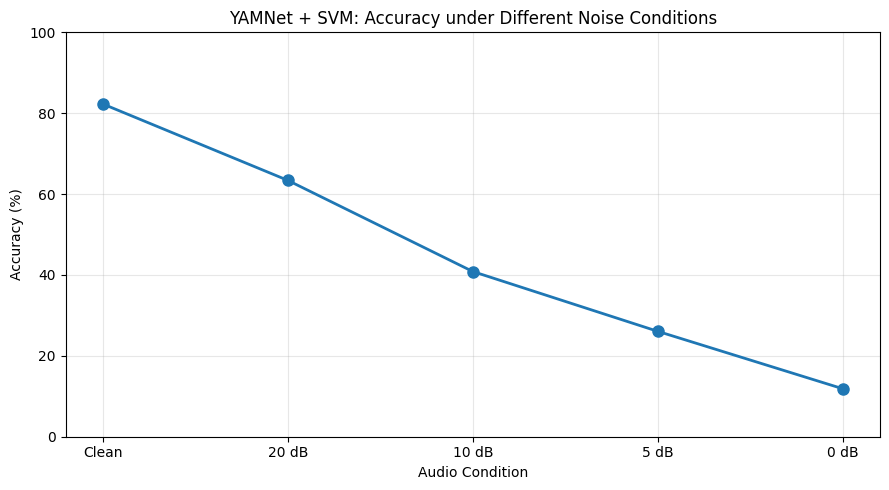

In [14]:

plt.figure(figsize=(9, 5))

plt.plot(
    summary_df["Condition"],
    summary_df["Accuracy"] * 100,
    marker="o",
    linewidth=2,
    markersize=8
)

plt.title(
    "YAMNet + SVM: Accuracy under Different Noise Conditions"
)

plt.xlabel("Audio Condition")
plt.ylabel("Accuracy (%)")

plt.grid(True, alpha=0.3)
plt.ylim(0, 100)

plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_PATH, "accuracy_vs_snr.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


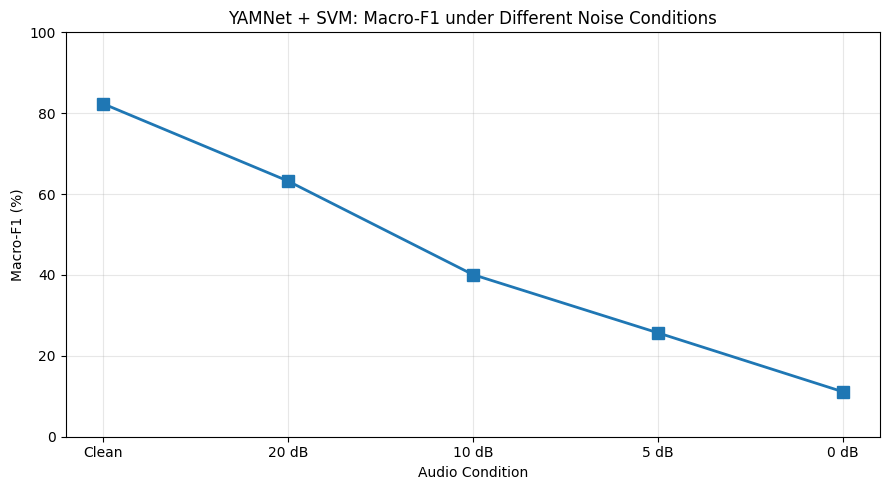

In [15]:

plt.figure(figsize=(9, 5))

plt.plot(
    summary_df["Condition"],
    summary_df["Macro_F1"] * 100,
    marker="s",
    linewidth=2,
    markersize=8
)

plt.title(
    "YAMNet + SVM: Macro-F1 under Different Noise Conditions"
)

plt.xlabel("Audio Condition")
plt.ylabel("Macro-F1 (%)")

plt.grid(True, alpha=0.3)
plt.ylim(0, 100)

plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_PATH, "macro_f1_vs_snr.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


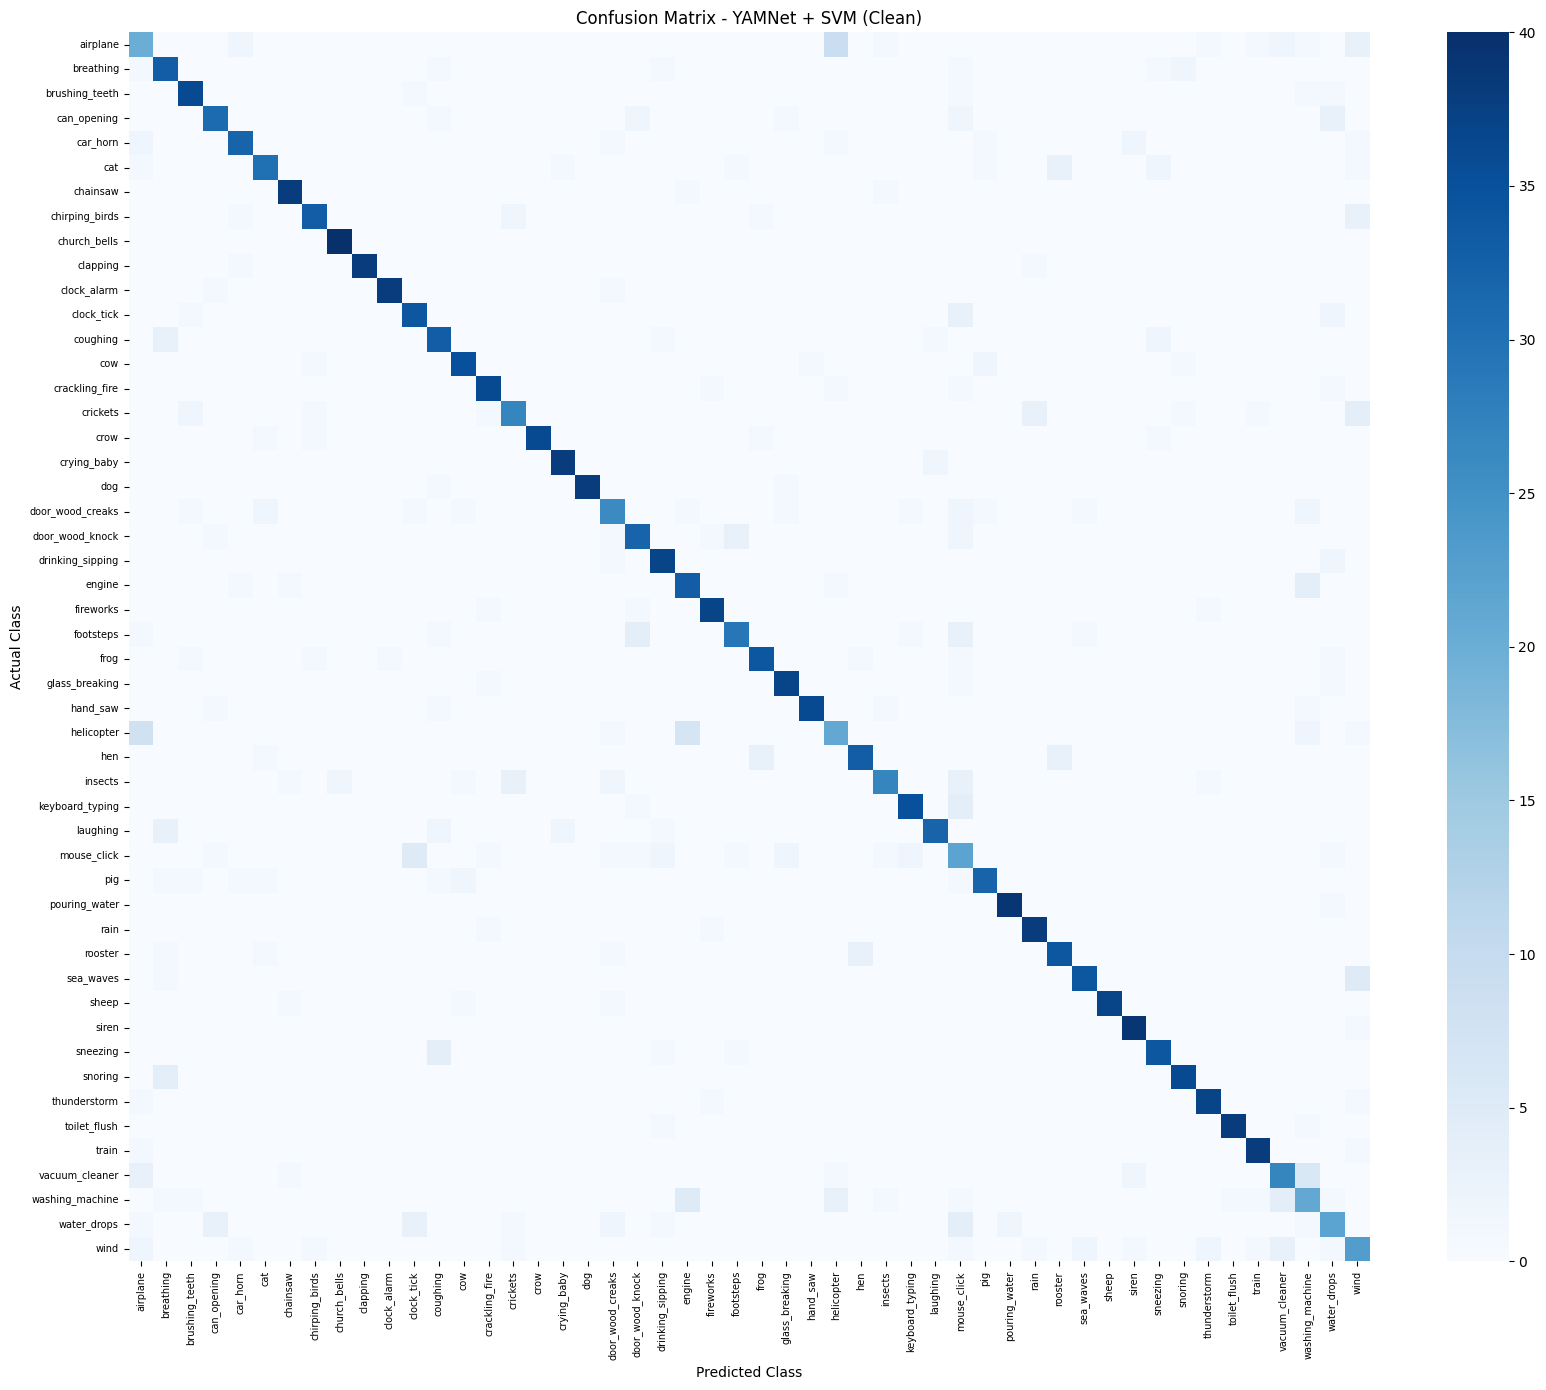

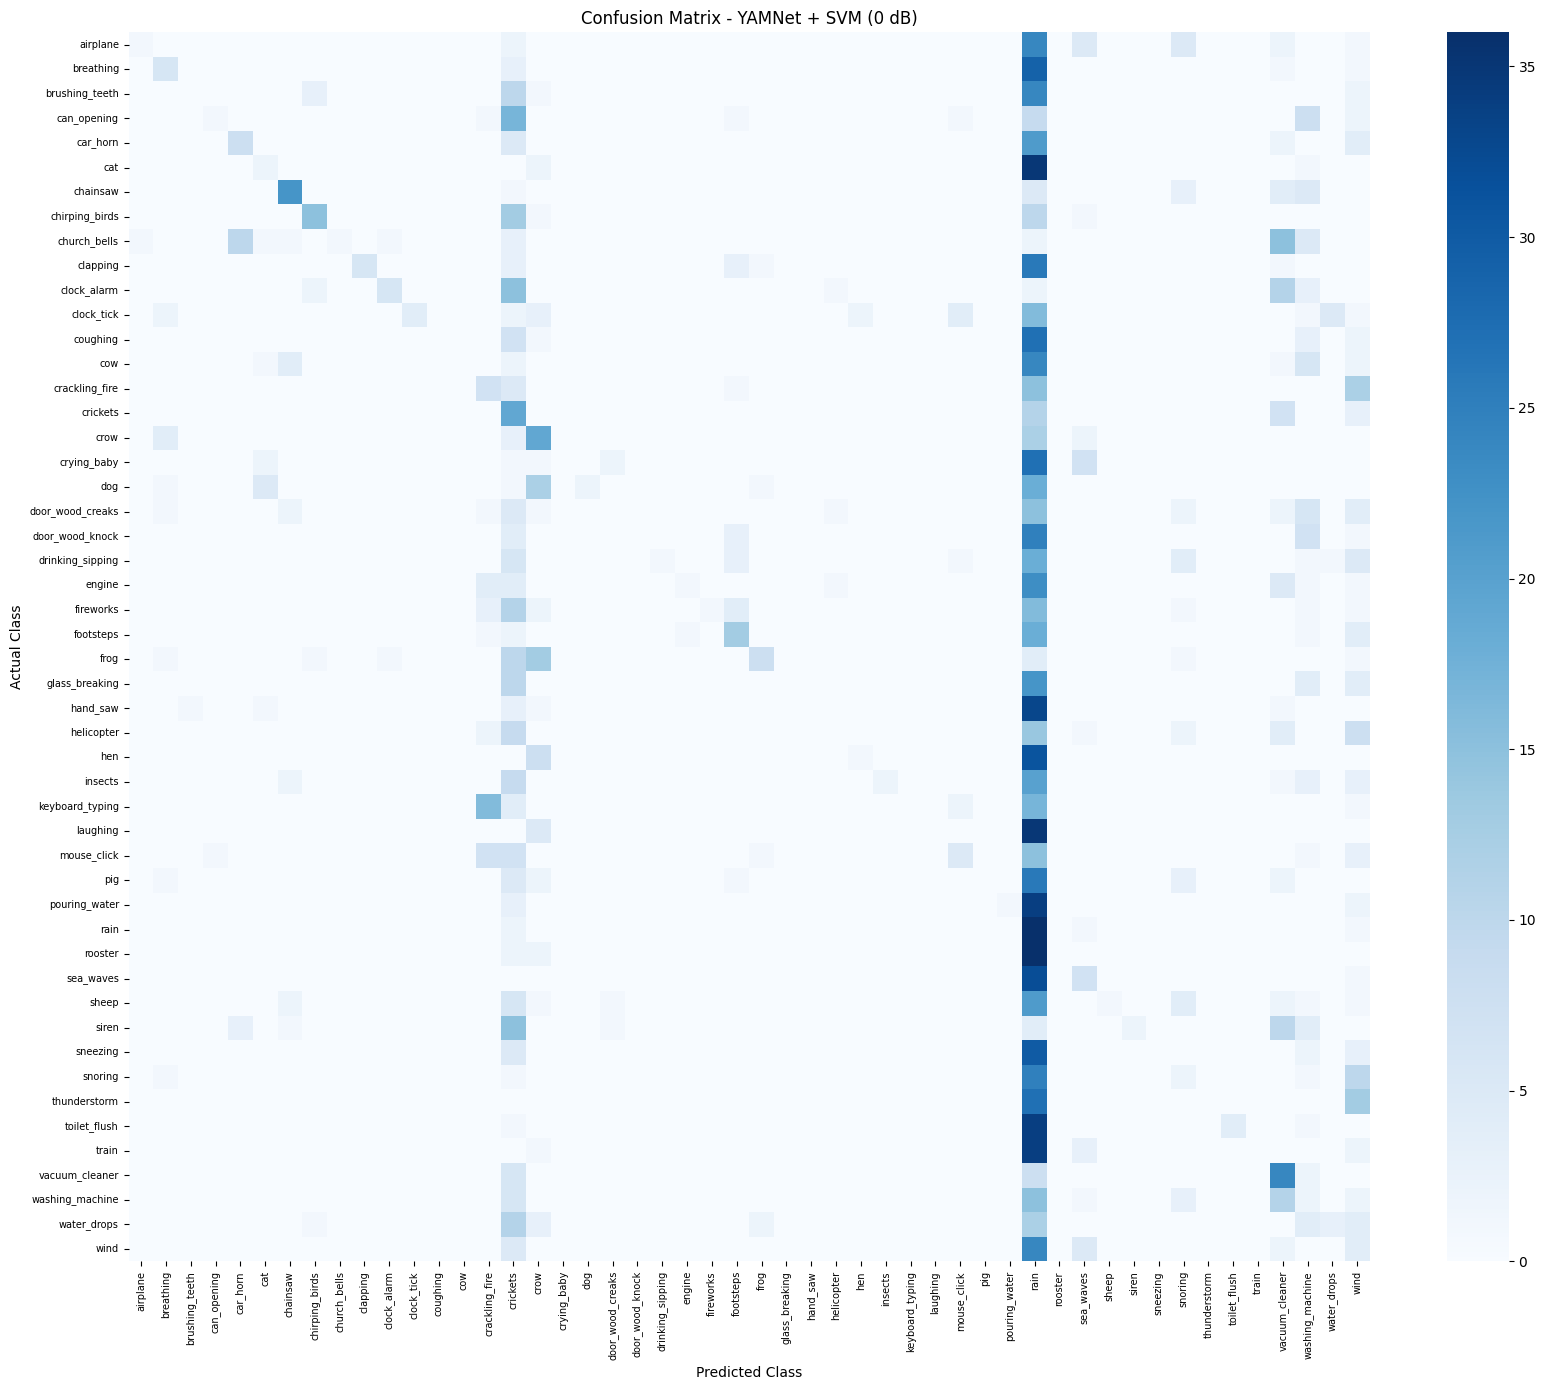

In [16]:

for condition in ["Clean", "0 dB"]:

    predictions = all_predictions[condition]

    cm = confusion_matrix(
        all_test_labels,
        predictions,
        labels=np.arange(NUM_CLASSES)
    )

    plt.figure(figsize=(17, 14))

    sns.heatmap(
        cm,
        cmap="Blues",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES,
        cbar=True
    )

    plt.title(
        f"Confusion Matrix - YAMNet + SVM ({condition})"
    )

    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")

    plt.xticks(rotation=90, fontsize=7)
    plt.yticks(rotation=0, fontsize=7)

    plt.tight_layout()

    safe_condition = condition.replace(" ", "_")

    plt.savefig(
        os.path.join(
            OUTPUT_PATH,
            f"confusion_matrix_{safe_condition}.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


<!-- solution3-narrative -->
## Class-wise analysis

Overall metrics can hide classes that fail disproportionately under noise. Per-class F1 scores and full classification reports are therefore generated for all five conditions.

This analysis also supports comparison with the MFCC-SVM and spectrogram-CNN solutions at the individual sound-class level.


In [17]:

per_class_results = []

for condition in CONDITIONS:

    predictions = all_predictions[condition]

    class_f1 = f1_score(
        all_test_labels,
        predictions,
        labels=np.arange(NUM_CLASSES),
        average=None,
        zero_division=0
    )

    for class_index, class_name in enumerate(CLASS_NAMES):

        per_class_results.append({
            "Condition": condition,
            "Class": class_name,
            "F1_Score": class_f1[class_index]
        })


per_class_df = pd.DataFrame(per_class_results)

display(per_class_df.head(20))

per_class_df.to_csv(
    os.path.join(OUTPUT_PATH, "per_class_f1.csv"),
    index=False
)


,Condition,Class,F1_Score
0,Clean,airplane,0.493827
1,Clean,breathing,0.758621
2,Clean,brushing_teeth,0.867470
3,Clean,can_opening,0.794872
4,Clean,car_horn,0.810127
5,Clean,cat,0.789474
6,Clean,chainsaw,0.926829
7,Clean,chirping_birds,0.846154
8,Clean,church_bells,0.975610
9,Clean,clapping,0.974359


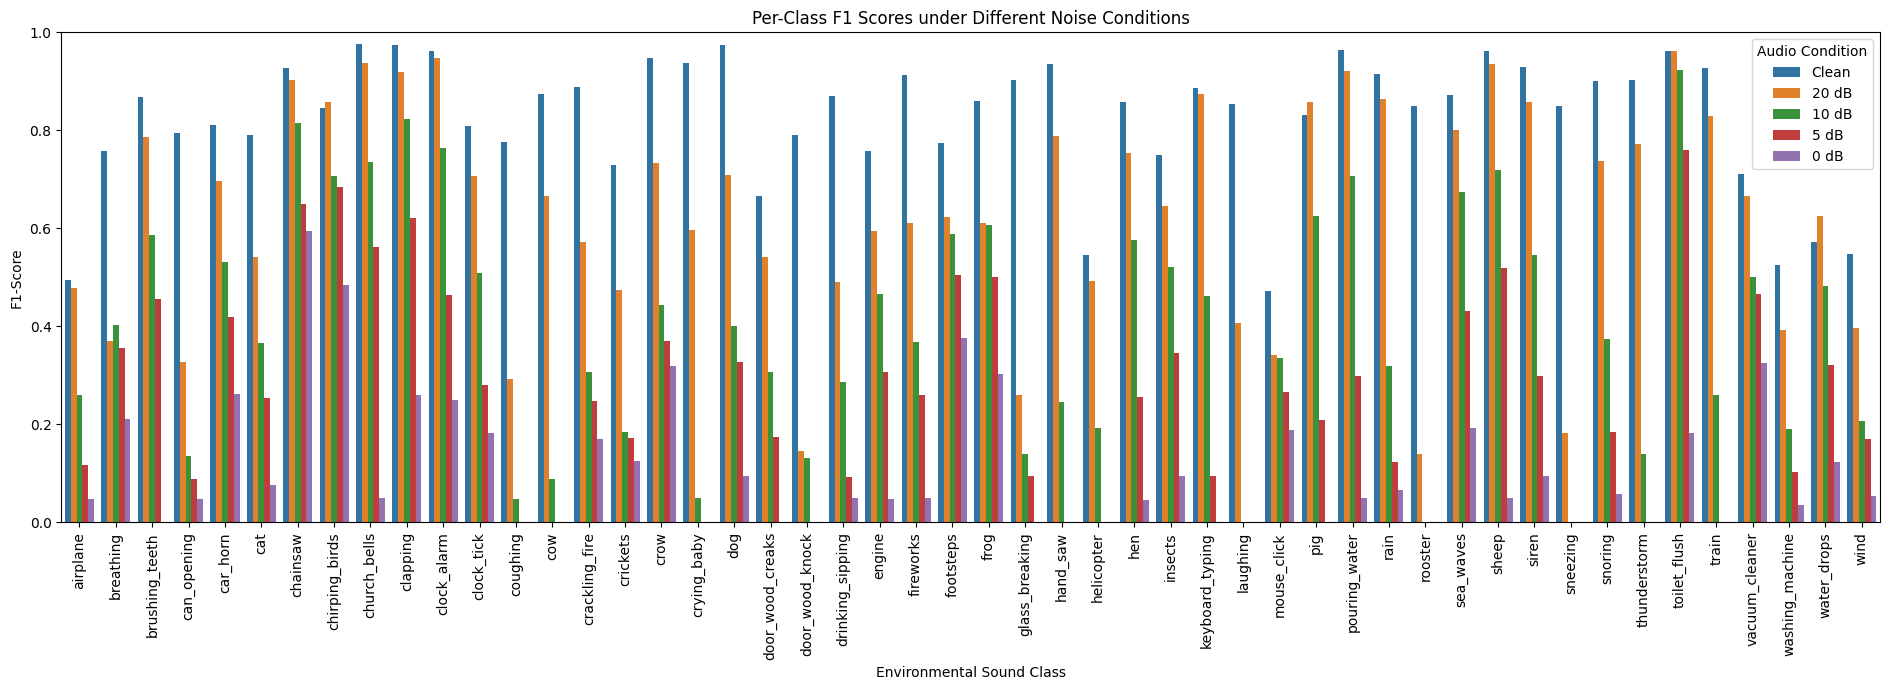

In [18]:

plt.figure(figsize=(19, 7))

sns.barplot(
    data=per_class_df,
    x="Class",
    y="F1_Score",
    hue="Condition"
)

plt.title("Per-Class F1 Scores under Different Noise Conditions")
plt.xlabel("Environmental Sound Class")
plt.ylabel("F1-Score")

plt.xticks(rotation=90)
plt.ylim(0, 1)

plt.legend(title="Audio Condition")
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_PATH, "per_class_f1_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [19]:

for condition in CONDITIONS:

    print("\n", "=" * 60)
    print("CLASSIFICATION REPORT:", condition)
    print("=" * 60)

    print(
        classification_report(
            all_test_labels,
            all_predictions[condition],
            labels=np.arange(NUM_CLASSES),
            target_names=CLASS_NAMES,
            zero_division=0
        )
    )



CLASSIFICATION REPORT: Clean
                  precision    recall  f1-score   support

        airplane       0.49      0.50      0.49        40
       breathing       0.70      0.82      0.76        40
  brushing_teeth       0.84      0.90      0.87        40
     can_opening       0.82      0.78      0.79        40
        car_horn       0.82      0.80      0.81        40
             cat       0.83      0.75      0.79        40
        chainsaw       0.90      0.95      0.93        40
  chirping_birds       0.87      0.82      0.85        40
    church_bells       0.95      1.00      0.98        40
        clapping       1.00      0.95      0.97        40
     clock_alarm       0.97      0.95      0.96        40
      clock_tick       0.77      0.85      0.81        40
        coughing       0.73      0.82      0.78        40
             cow       0.88      0.88      0.88        40
  crackling_fire       0.88      0.90      0.89        40
        crickets       0.79      0.68    

<!-- solution3-narrative -->
## Final classifier and reusable artifacts

After cross-validation, a final SVM pipeline is trained on all clean embeddings. This model is intended as a reusable classifier for already-extracted YAMNet embeddings; YAMNet itself remains the separate frozen feature extractor.

Classifier size and inference latency are recorded separately from embedding-extraction time because they represent different computational stages.


In [20]:

final_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        C=10,
        gamma="scale"
    ))
])

final_train_start = time.time()

final_model.fit(X[:, 0, :], y)

final_training_time = time.time() - final_train_start

# Save the final SVM pipeline
FINAL_MODEL_PATH = os.path.join(
    OUTPUT_PATH,
    "yamnet_svm_final.joblib"
)

joblib.dump(final_model, FINAL_MODEL_PATH)

model_size_mb = (
    os.path.getsize(FINAL_MODEL_PATH) / (1024 ** 2)
)

# Measure classifier-only inference latency
test_sample = X[:100, 0, :]

# Warm-up
final_model.predict(test_sample[:5])

start = time.perf_counter()

for _ in range(10):
    final_model.predict(test_sample)

elapsed = time.perf_counter() - start

average_inference_ms = (
    elapsed / (10 * len(test_sample))
) * 1000

print("Final model training time:", round(final_training_time, 2), "seconds")
print("SVM pipeline size:", round(model_size_mb, 3), "MB")
print("Average classifier inference time:", round(average_inference_ms, 4), "ms/sample")


Final model training time: 0.57 seconds
SVM pipeline size: 12.601 MB
Average classifier inference time: 1.1673 ms/sample


<!-- solution3-narrative -->
## Save reproducibility outputs

The notebook exports fold-wise metrics, condition summaries, class-wise F1 scores, class mappings, and recording-level predictions. These lightweight files are sufficient to verify and reproduce the reported tables and figures without committing the large embedding cache.


In [21]:

fold_results.to_csv(
    os.path.join(OUTPUT_PATH, "fold_wise_results.csv"),
    index=False
)

summary_df.to_csv(
    os.path.join(OUTPUT_PATH, "model3_summary.csv"),
    index=False
)

per_class_df.to_csv(
    os.path.join(OUTPUT_PATH, "per_class_f1.csv"),
    index=False
)

prediction_df = pd.DataFrame({
    "Filename": metadata["filename"],
    "Actual_Class": label_encoder.inverse_transform(y)
})

for condition in CONDITIONS:

    prediction_df[f"Prediction_{condition}"] = (
        label_encoder.inverse_transform(
            all_predictions[condition]
        )
    )

prediction_df.to_csv(
    os.path.join(OUTPUT_PATH, "model3_predictions.csv"),
    index=False
)

pd.DataFrame({
    "Label": np.arange(NUM_CLASSES),
    "Class": CLASS_NAMES
}).to_csv(
    os.path.join(OUTPUT_PATH, "class_mapping.csv"),
    index=False
)



<!-- solution3-narrative -->
## Export Colab results

The final cell packages the generated artifacts into a ZIP archive for download from Colab. Large embeddings and trained-model files should be stored outside Git when publishing the project.


In [22]:

import shutil
from google.colab import files

ZIP_OUTPUT = "/content/model3_results.zip"

shutil.make_archive(
    "/content/model3_results",
    "zip",
    OUTPUT_PATH
)

files.download(ZIP_OUTPUT)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<!-- solution3-narrative -->
## Interpretation and conclusion

YAMNet embeddings with an SVM produced the strongest of the three project solutions. Accuracy decreased from **82.30% on clean audio** to **63.40% at 20 dB**, **40.85% at 10 dB**, **26.05% at 5 dB**, and **11.85% at 0 dB**.

The result shows that external AudioSet pretraining transfers useful acoustic structure to ESC-50. However, the 0 dB result retains only about **14.4% of clean accuracy**, so pretraining improves relative robustness without providing noise immunity.

### Limitations

- Only additive Gaussian noise is tested.
- YAMNet benefits from external AudioSet pretraining, while the other project models learn from ESC-50 folds only.
- The experiment does not model real microphones, rooms, reverberation, codecs, or natural background recordings.
- Computational timings were recorded in the available Colab environment and are not a controlled hardware benchmark.

### Suggested next steps

Evaluate real background sounds, reverberation, microphone changes, noise-aware training, and domain-adaptation methods while preserving the same leakage-controlled outer-fold protocol.
